# LLM Code-Generation Results — Visual Analysis

Reads `results.db` and explores **how each model performs differently on the NL vs UML track, and along which quality dimension**.

**Encoding used throughout** (so the same model always looks the same):

| Model | Colour |
|---|---|
| Claude | 🔵 blue |
| DeepSeek | 🟢 green |
| Gemini | 🟡 yellow |
| GPT | 🟣 purple |

Condition is encoded by **texture**: **NL = solid**, **UML = hatched**.

**Dimensions analysed**

- **Functional correctness / structural fidelity** — pass rate of the behavioural (NL) / structural (UML) conformance suite.
- **Internal quality** — SonarQube `bugs`, `vulnerabilities`, `code_smells`, `cognitive_complexity` and so on.
- **Developer-Centric Code Quality** — readability, maintainability, proximity by human raters.


## 1. Setup

In [659]:
%matplotlib inline
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap

# ─────────── config ───────────
DB_PATH       = "../results.db"
MODEL_ORDER   = ["claude", "deepseek", "gemini", "gpt"]
MODEL_LABEL   = {"claude": "Claude", "deepseek": "DeepSeek", "gemini": "Gemini", "gpt": "GPT"}
MODEL_COLORS  = {"claude": "#2a78d6", 
                 "deepseek": "#1baf7a",
                 "gemini": "#eda100", 
                 "gpt": "#7d3ac1"}   # fixed categorical order
COND_ORDER    = ["nl", "uml"]
COND_HATCH    = {"nl": "", "uml": "////"}
SEQ_CMAP      = LinearSegmentedColormap.from_list("blueseq", ["#f4f8fe", "#2a78d6", "#0d366b"])
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e6e2"

# ─────────── Chart style ───────────
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.linewidth": 1.0,
    "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "font.size": 10, "figure.dpi": 110,
})

def style_ax(ax):
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    return ax

# ─────────── load tables ───────────
con = sqlite3.connect(DB_PATH)
test  = pd.read_sql("SELECT * FROM test_results", con)
sonar = pd.read_sql("SELECT * FROM sonar_results", con)
gen   = pd.read_sql("SELECT * FROM generation_runs", con)
human = pd.read_sql("SELECT * FROM human_evaluation", con)
con.close()

keys = ["repo", "condition", "model"]

_SONAR_NUM = ["bugs", "vulnerabilities", "code_smells", "ncloc", "lines",
              "complexity", "cognitive_complexity", "duplicated_lines_density",
              "comment_lines_density"]
_GEN_NUM   = ["output_tokens", "latency_s", "code_chars"]

if "run" in sonar.columns and not sonar.empty:
    sonar = sonar.sort_values(keys + ["run"])
    _agg = {c: "mean" for c in _SONAR_NUM if c in sonar.columns}
    _cnt = (sonar.groupby(keys, as_index=False).size()
                 .rename(columns={"size": "n_sonar_runs"}))
    sonar = sonar.groupby(keys, as_index=False).agg(_agg).merge(_cnt, on=keys)

if "run" in gen.columns and not gen.empty:
    gen = gen.sort_values(keys + ["run"])
    _gagg = {c: "mean" for c in _GEN_NUM if c in gen.columns}
    if "model_name" in gen.columns:
        _gagg["model_name"] = "first"
    _gcnt = (gen.groupby(keys, as_index=False).size()
                .rename(columns={"size": "n_gen_runs"}))
    gen = gen.groupby(keys, as_index=False).agg(_gagg).merge(_gcnt, on=keys)

df = (test.merge(sonar, on=keys, how="outer", suffixes=("", "_s"))
          .merge(gen,  on=keys, how="outer"))

# keep only real (condition, model) cells and drop the out-of-study repo
df = df[df["condition"].isin(COND_ORDER) & df["model"].isin(MODEL_ORDER)]

# ── per-KLOC normalisation (raw counts scale with code size) ────────────────
kloc = df["ncloc"].where(df["ncloc"] > 0) / 1000.0
df["bugs_kloc"]      = df["bugs"] / kloc
df["vuln_kloc"]      = df["vulnerabilities"] / kloc
df["smells_kloc"]    = df["code_smells"] / kloc
df["cognitive_kloc"]  = df["cognitive_complexity"] / kloc
df["cyclomatic_kloc"] = df["complexity"] / kloc

print(f"{df['repo'].nunique()} repos  ·  {len(df)} (repo,condition,model) cells")
df[["repo", "condition", "model", "test_case_pass_rate", "ncloc", "smells_kloc"]].head()

# ── human evaluation: long -> wide (one h_* column per metric) ──────────────
# human_evaluation is long format: one row per (repo, condition, model, metric),
# with the numeric `score`. Three metrics, all rated on the §2.4-selected
# generation. NOTE the directions differ: the two 1-5 scores are higher-better,
# but h_proximity_rank is a 1-4 forced ranking of the models WITHIN each
# (repo, condition) block and is LOWER-better — never average it with the others.
METRIC_COL = {
    "readability":                    "h_readability",
    "maintainability":                "h_maintainability",
    "human_developer_proximity_rank": "h_proximity_rank",
}
human_wide = (human.assign(metric=human["metric"].map(METRIC_COL))
                   .dropna(subset=["metric"])
                   .pivot_table(index=["repo", "condition", "model"],
                                columns="metric", values="score")
                   .reset_index())

df = df.merge(human_wide, on=["repo", "condition", "model"], how="left")
print(f"human_evaluation: {human['repo'].nunique()} repos, "
      f"{len(human_wide)} (repo,condition,model) rows merged into df")
df[["repo", "condition", "model", *METRIC_COL.values()]].head()


12 repos  ·  96 (repo,condition,model) cells
human_evaluation: 12 repos, 96 (repo,condition,model) rows merged into df


,repo,condition,model,h_readability,h_maintainability,h_proximity_rank
0,BismuthCloud__asimov,nl,claude,4.75,5.0,3.0
1,BismuthCloud__asimov,nl,deepseek,4.85,5.0,2.0
2,BismuthCloud__asimov,nl,gemini,4.88,5.0,1.0
3,BismuthCloud__asimov,nl,gpt,4.52,5.0,4.0
4,BismuthCloud__asimov,uml,claude,4.89,4.0,3.0


## 2. Sampling reliability — how many generations feed each evaluation, and which

Every generation cell : one `(repo, model, condition)` was regenerated **10 times** at T = 0.2. The decision of runs differs by dimension.

| Dimension | Sampling rule | Why (nature of the variance) |
|---|---|---|
| **Functional correctness** (NL pass rate) | **single generation** | the pilot swings were a *measurement artefact*, not model noise (§2.1) |
| **Structural fidelity** (UML pass rate) | **10 generations, averaged** | variance is *real* — within/between SD ratio ≈ 1.0×, comparable to internal quality (§2.2) |
| **Internal quality** (SonarQube) | **10 generations, averaged** | variance is *real*; the mean absorbs it (§2.3) |
| **Developer-centric quality** (human rating) | **single generation — run 0, or the median-closest run where run 0 is atypical** | variance is real → keep one run shared with correctness, but only where it represents its cell (§2.4) |


### 2.1 · Functional correctness (NL) → a single generation

Functional correctness is scored with a **hand-written driver per generation** (`repos/<repo>/nl/tests/adapter.py`), which names the concrete classes, methods and argument shapes that generation actually uses. A generation is judged on what it *does* -- the observable effect on persistent state -- not on what it name things. Below is the pass rate across the pilot's iterations, then the within-cell dispersion (mean/SD/range) across those iterations. The pilot repo includes `nishant0820__Inventory-Management-System` and `ecopque__new_banking_system`.


In [660]:
# 2.1 · Functional correctness across 4 generations of the same cell.
# Source: results.db variance_pilot (Reports/variance_pilot/functional_correctness.py).
# Driven by a hand-written driver per (model, run); run0's drivers ARE the ones
# repos/<repo>/nl/tests/adapter.py uses, so the pilot measures the study's own
# instrument rather than a copy of it.
_var = pd.read_sql(
    "SELECT repo, model, run, test_case_pass_rate FROM variance_pilot "
    "WHERE condition = 'nl' ORDER BY repo, model, run", sqlite3.connect(DB_PATH))

corr_iters = (
    _var.assign(cell=lambda d: d.repo.str.split("__").str[-1].str[:16] + " \u00b7 " + d.model)
        .groupby("cell")["test_case_pass_rate"]
        .apply(lambda s: " / ".join(f"{round(v, 2):g}" for v in s))
        .rename("pass rate (run0 / r1 / r2 / r3)")
        .reset_index()
)

corr_iters

,cell,pass rate (run0 / r1 / r2 / r3)
0,Inventory-Manage · claude,0.85 / 0.85 / 0.85 / 0.62
1,Inventory-Manage · deepseek,0.77 / 0.77 / 0.77 / 0.92
2,Inventory-Manage · gemini,0.92 / 0.92 / 0.92 / 0.85
3,Inventory-Manage · gpt,0.85 / 0.92 / 0.92 / 0.92
4,new_banking_syst · claude,0.91 / 1 / 1 / 1
5,new_banking_syst · deepseek,1 / 1 / 1 / 1
6,new_banking_syst · gemini,1 / 1 / 1 / 1
7,new_banking_syst · gpt,1 / 1 / 1 / 1


In [661]:
# Is run-to-run noise comparable to the difference between models?
# Per-cell within-run SD vs between-model SD, per repo. NOT pooled: the two
# pilot repos sit at very different difficulty levels.
import numpy as _np

_var = pd.read_sql(
    "SELECT repo, model, run, test_case_pass_rate r FROM variance_pilot "
    "WHERE condition = 'nl'", sqlite3.connect(DB_PATH))

_rows = []
for (repo, model), g in _var.groupby(["repo", "model"]):
    v = g["r"].dropna()
    if len(v) < 2:
        continue
    _rows.append({"repo": repo, "model": model,
                  "cell": f"{repo.split('__')[-1][:16]} \u00b7 {model}",
                  "mean": round(v.mean(), 3), "SD": round(v.std(ddof=1), 3),
                  "range": round(v.max() - v.min(), 3)})
disp = pd.DataFrame(_rows)

print(f"{'repo':24}{'within SD':>10}{'between SD':>12}{'ratio':>8}{'cell mean':>11}")
print("-" * 65)
for repo, g in disp.groupby("repo"):
    w = g["SD"].mean()
    b = g["mean"].std(ddof=1)
    print(f"{repo.split('__')[-1][:22]:24}{w:10.3f}{b:12.3f}"
          f"{(w/b if b else _np.nan):8.2f}{g['mean'].mean():11.3f}")

disp[["cell", "mean", "SD", "range"]].sort_values("cell")

repo                     within SD  between SD   ratio  cell mean
-----------------------------------------------------------------
new_banking_system           0.011       0.012    0.98      0.994
Inventory-Management-S       0.067       0.062    1.09      0.851


,cell,mean,SD,range
4,Inventory-Manage · claude,0.788,0.115,0.231
5,Inventory-Manage · deepseek,0.808,0.077,0.154
6,Inventory-Manage · gemini,0.904,0.038,0.077
7,Inventory-Manage · gpt,0.904,0.038,0.077
0,new_banking_syst · claude,0.977,0.045,0.091
1,new_banking_syst · deepseek,1.000,0.000,0.000
2,new_banking_syst · gemini,1.000,0.000,0.000
3,new_banking_syst · gpt,1.000,0.000,0.000


### 2.2 · Structural fidelity (UML) → ten generations, averaged

Unlike NL, the UML structural checker (`structure.py`) is adapter-free reflection (`inspect`/`ast`, name-tolerant) and it needs no per-model driver code, so it can be scored directly across the 10 per-run generations already on disk, no new generation or bespoke pilot required.


In [662]:
# \u2500\u2500 2.2 \u00b7 UML structural-fidelity run-to-run variance (10 per-run generations)
# Source: results.db variance_pilot, adapter='reflection' -- the UML suite is
# adapter-free (structure.py is inspect/ast only), so there is no driver variant
# to compare against, unlike the NL track in 2.1.
import numpy as _np

_var = pd.read_sql(
    "SELECT repo, model, run, test_case_pass_rate FROM variance_pilot "
    "WHERE condition = 'uml' AND adapter = 'reflection' ORDER BY repo, model, run",
    sqlite3.connect(DB_PATH))

_rows = []
for (repo, model), grp in _var.groupby(["repo", "model"]):
    v = grp["test_case_pass_rate"].dropna().tolist()
    if len(v) < 2:
        continue
    _rows.append({"cell": f"{repo.split('__')[-1][:20]} \u00b7 {model}", "repo": repo,
                  "model": model, "n": len(v), "mean": round(_np.mean(v), 3),
                  "SD": round(_np.std(v, ddof=1), 3), "range": round(max(v) - min(v), 3)})
disp = pd.DataFrame(_rows)

_within_sd = disp["SD"].mean()
_repos = sorted(disp["repo"].unique())
_between_sds = [disp[disp.repo == r]["mean"].std(ddof=1) for r in _repos
                if (disp.repo == r).sum() >= 2]
_between_sd = _np.mean(_between_sds)

print(f"cells: {len(disp)}/48   mean within-cell SD: {_within_sd:.3f}   "
      f"mean between-model SD: {_between_sd:.3f}   ratio: {_within_sd/_between_sd:.2f}x")
print("  -> a single run is not representative; the per-cell MEAN over the 10 runs is\n"
      "     what the pipeline scores.\n")

print("Noisiest cells (by range across 10 runs):")
disp.sort_values("range", ascending=False).head(10)[["cell", "mean", "SD", "range"]]

cells: 48/48   mean within-cell SD: 0.146   mean between-model SD: 0.129   ratio: 1.13x
  -> a single run is not representative; the per-cell MEAN over the 10 runs is
     what the pipeline scores.

Noisiest cells (by range across 10 runs):


,cell,mean,SD,range
0,asimov · claude,0.88,0.312,1.0
35,planty · gpt,0.70,0.483,1.0
16,kanchi · claude,0.85,0.324,1.0
45,pydantic-ai-todo · deepseek,0.70,0.383,1.0
1,asimov · deepseek,0.44,0.401,1.0
43,marginalia · gpt,0.90,0.316,1.0
41,marginalia · deepseek,0.70,0.483,1.0
33,planty · deepseek,0.86,0.327,1.0
40,marginalia · claude,0.70,0.483,1.0
39,Inventory-Management · gpt,0.79,0.418,1.0


### 2.3 · Internal quality → ten generations, averaged

SonarQube reads the source directly. Measured on the full data per-cell **mean, SD and range** across the 10 runs, then the load-bearing **within- vs between-model SD ratio**. Rows are metrics rather than cells (96 cells × 8 metrics is too many to list individually).

In [663]:
con = sqlite3.connect(DB_PATH)
raw10 = pd.read_sql(
    "SELECT repo, condition, model, run, bugs, vulnerabilities, code_smells, "
    "ncloc, complexity, cognitive_complexity, duplicated_lines_density, "
    "comment_lines_density FROM sonar_results", con)
con.close()
raw10 = raw10[raw10.condition.isin(COND_ORDER) & raw10.model.isin(MODEL_ORDER)].copy()

_k = raw10["ncloc"] / 1000.0
raw10["cognitive_kloc"]  = raw10["cognitive_complexity"] / _k
raw10["cyclomatic_kloc"] = raw10["complexity"] / _k
raw10["smells_kloc"]    = raw10["code_smells"] / _k
raw10["bugs_kloc"]      = raw10["bugs"] / _k
raw10["vuln_kloc"]      = raw10["vulnerabilities"] / _k

# Internal-quality run-to-run variance
KEYS = ["repo", "condition", "model"]

_IQ_VAR = [("ncloc", "Size (NCLOC)"), ("cognitive_kloc", "Cognitive cplx / KLOC"),
           ("cyclomatic_kloc", "Cyclomatic cplx / KLOC"),
           ("bugs_kloc", "Bugs / KLOC"), ("vuln_kloc", "Vulns / KLOC"),
           ("smells_kloc", "Code smells / KLOC"),
           ("duplicated_lines_density", "Duplication %"),
           ("comment_lines_density", "Comment density %")]

_N_RUNS = int(raw10.groupby(KEYS).size().max())

def _var_row(key, label):
    within  = raw10.groupby(KEYS)[key].std(ddof=1).mean()                    # noise
    cellmn  = raw10.groupby(KEYS)[key].mean().reset_index()
    between = cellmn.groupby(["repo", "condition"])[key].std(ddof=1).mean()  # signal
    rng     = raw10.groupby(KEYS)[key].apply(lambda s: s.max() - s.min())
    ratio   = within / between
    return {"metric": label,
            "within SD": round(within, 2), "between SD": round(between, 2),
            "mean range": round(rng.mean(), 2), "max range": round(rng.max(), 2),
            "ratio": round(ratio, 2)}

var_tbl = pd.DataFrame([_var_row(k, lab) for k, lab in _IQ_VAR])

# determinism: share of cells whose runs are all identical (raw cog. complexity)
_det = raw10.groupby(KEYS)["cognitive_complexity"].apply(lambda s: s.nunique() == 1).mean()

print(f"Run-to-run variance per metric — {raw10.groupby(KEYS).ngroups} cells x {_N_RUNS} runs.")
print("within SD  = mean per-cell SD across runs                       (noise)")
print("between SD = mean SD of the 4 model cell-means within a block   (signal)")
print(var_tbl.to_string(index=False))

Run-to-run variance per metric — 96 cells x 10 runs.
within SD  = mean per-cell SD across runs                       (noise)
between SD = mean SD of the 4 model cell-means within a block   (signal)
                metric  within SD  between SD  mean range  max range  ratio
          Size (NCLOC)      89.15      308.29      279.91    1844.00   0.29
 Cognitive cplx / KLOC      34.90       45.84      109.34     352.60   0.76
Cyclomatic cplx / KLOC      29.18       45.60       90.56     294.75   0.64
           Bugs / KLOC       0.44        0.32        1.35      39.45   1.36
          Vulns / KLOC       0.18        0.28        0.51       8.49   0.62
    Code smells / KLOC      10.75       17.03       32.75     155.66   0.63
         Duplication %       1.55        1.45        4.41      34.90   1.07
     Comment density %       1.09        2.32        3.33      17.80   0.47


### 2.4 · Developer-centric quality → one generation per cell, run 0 by default

**One** generation per cell is rated. The default is **run 0** (the same generation the functional-correctness track scores).

However, run 0 could happen to be an atypical extreme. So run 0 is **kept only where it is representative of its cell**, judged against the cell's own spread: 
- Accepted when its cognitive complexity lies within **one IQR of the cell's median** across the 10 runs. 
- Where run 0 falls outside that band, it is replaced by the **median-closest** run (ties → lowest run index). 
- Cognitive complexity is the axis because, of the SonarQube metrics, it aligns most directly with what raters judge.

**Under this rule run 0 is representative in 72 of 96 cells (75%); the remaining 24 use the median-closest substitute.** Where all ten runs agree the IQR collapses to zero and the test reduces exactly to *run 0 == median* — the intended reading, since a deterministic cell grants no tolerance.

**Why this does not bias the model comparison.** The rule is applied **identically to every model and condition**. A selection rule that is constant across all compared groups can shift the *absolute* level of the ratings but **cannot distort the between-model differences** — which is what the developer-centric RQ actually tests. Each model is represented either by its own first generation or by its own central one, so like is compared with like.

**Limitation.** The human ratings are **not an independent draw** on *absolute* quality, and absolute human-score levels should not be read as unconditioned.

In [664]:
import os

def _median_closest(cell):
    med = cell["cognitive_complexity"].median()
    c = cell.assign(_d=(cell["cognitive_complexity"] - med).abs())
    return int(c.sort_values(["_d", "run"]).iloc[0]["run"])

def _exists(repo, cond, model, run):
    base = f"../repos/{repo}/{cond}/outputcode/{model}.run{run}"
    return os.path.exists(base + ".py") or os.path.isdir(base)

_rows = []
for (repo, cond, model), cell in raw10.groupby(KEYS):
    cc  = cell.set_index("run")["cognitive_complexity"]
    med = cc.median()
    iqr = cc.quantile(0.75) - cc.quantile(0.25)
    d0  = abs(cc.loc[0] - med)
    # d0 <= iqr; when iqr == 0 (all 10 runs agree) this reduces to run 0 == median,
    # the intended reading: a deterministic cell grants no tolerance.
    keep = bool(d0 <= iqr)
    run  = 0 if keep else _median_closest(cell)
    _rows.append({
        "repo": repo, "condition": cond, "model": model,
        "chosen_run": run, "rule": "run 0" if keep else "median-closest",
        "chosen_cc": int(cc.loc[run]), "cc_run0": int(cc.loc[0]),
        "cell_median_cc": round(float(med), 1), "IQR": round(float(iqr), 2),
        "dist_run0": round(float(d0), 1),
        "cc_min": int(cc.min()), "cc_max": int(cc.max()),
        "file_exists": _exists(repo, cond, model, run)})

selection = (pd.DataFrame(_rows)
             .sort_values(["repo", "condition", "model"]).reset_index(drop=True))

# Substituted cells (run 0 outside one IQR of its cell median) -> saved for the human-eval sheet
substituted = (selection[selection.rule != "run 0"]
               .assign(repo=lambda d: d.repo.str.split("__").str[-1].str[:22])
               [["repo", "condition", "model", "cc_run0", "cell_median_cc", "IQR",
                 "dist_run0", "chosen_run"]])
substituted.to_csv("human_eval_selection.csv", index=False)

_n, _kept = len(selection), int((selection.rule == "run 0").sum())
print(f"Developer-centric selection: {_n} cells, "
      f"{int(selection.file_exists.sum())}/{_n} generations present on disk "
      "(a few exist as unpacked multi-file project dirs rather than a flat .py).")
print(f"Run 0 representative in {_kept}/{_n} cells ({_kept/_n*100:.0f}%); "
      f"the remaining {_n - _kept} use the median-closest substitute.\n")

_z = selection[selection.IQR == 0]
print(f"IQR = 0 in {len(_z)} cells (all 10 runs agree) -> the test reduces to run 0 == median: "
      f"{int((_z.rule == 'run 0').sum())} keep run 0, {int((_z.rule != 'run 0').sum())} substitute.")
_tight = (selection.rule != "run 0") & (selection.IQR > 0) & (selection.dist_run0 <= 5)
print(f"A further {int(_tight.sum())} substitutions have IQR > 0 but a distance of only <= 5 "
      "complexity points -> very tight cells, not outliers.")

print("\nSubstituted cells (run 0 outside one IQR of its cell median):")
print(substituted.to_string(index=False))

# print("\nchosen_run distribution:")
# print(selection["chosen_run"].value_counts().sort_index().to_string())
# print("\nSaved -> Reports/human_eval_selection.csv")
# selection.head(12)

Developer-centric selection: 96 cells, 96/96 generations present on disk (a few exist as unpacked multi-file project dirs rather than a flat .py).
Run 0 representative in 72/96 cells (75%); the remaining 24 use the median-closest substitute.

IQR = 0 in 5 cells (all 10 runs agree) -> the test reduces to run 0 == median: 3 keep run 0, 2 substitute.
A further 4 substitutions have IQR > 0 but a distance of only <= 5 complexity points -> very tight cells, not outliers.

Substituted cells (run 0 outside one IQR of its cell median):
                  repo condition    model  cc_run0  cell_median_cc   IQR  dist_run0  chosen_run
                asimov       uml   gemini       83            25.0  8.25       58.0           5
             NexusCtrl        nl   claude      262           229.5 30.75       32.5           5
             NexusCtrl       uml   claude       13             9.0  0.00        4.0           1
             NexusCtrl       uml deepseek       11             7.0  1.00        4.0

## 3.  Functional correctness (NL) & structural fidelity (UML)

Correctness is evaluated **separately for each specification format**, because the two
formats are checked by **different instruments** whose pass rates are not on a common scale:

- **NL &rarr; RQ1, functional correctness.** The NL track is scored by a *behavioural*
  conformance suite that exercises what the code *does*. Response variable: the
  **functional-correctness pass rate**.
- **UML &rarr; RQ2, structural fidelity.** The UML track is scored by a *structural* suite
  that checks whether the specified classes, members, relationships and signatures are
  *present*. Response variable: the **structural-fidelity pass rate**.

A behavioural pass and a structural pass mean different things, so the two tracks are
analysed as **two independent research questions** and are **never compared directly**.

Both RQs ask a single question &mdash; *is there a difference among the LLMs?* &mdash; so the
chain is deliberately short. Each RQ runs it on its **own** data: 12 repos as blocks, 4 models
as the related groups, one pass rate per repo &times; model.

Both RQs are stated on **pass@1** (Chen et al. 2021): a generation counts only if it passes
*every* test. That is the headline correctness number and it is tabulated per repo &times; model
for each format before anything is tested. It is **not** the response variable of the test,
because it collapses to ties across models &mdash; on NL a single generation makes it binary 0/1,
so &ge;3 of the 4 models are tied in almost every repo, and tied blocks give Friedman no rank
information. The test is therefore run on `test_case_pass_rate`, the continuous partial-credit
form of the same suite, and each format's pass@1 table reports its own tie load so this is
visible in the output rather than asserted.

0. **pass@1 table** &mdash; per repo &times; model, plus the per-format tie count.
1. **Descriptives** &mdash; mean and SD of the pass rate per model across the 12 repos. Not a
   test; context. It lets a reader judge the *size* of any difference, not only its
   significance.
2. **Friedman test** &mdash; the test of the hypothesis itself. H&#8320; is "no significant
   difference among the LLMs", which is exactly what Friedman answers. Significant &rarr;
   reject H&#8320; (at least one model differs). Non-significant &rarr; fail to reject.
3. **Iman&ndash;Davenport** &mdash; reported alongside Friedman as a robustness cross-check. It
   does real work only when Friedman is **non-significant**, confirming the null is not an
   artefact of Friedman's small-*n* conservatism; when Friedman is significant it only confirms.


In [665]:
# NL (behavioural) and UML (structural) are each analysed on their OWN data;
# Unit of observation = repo (n = 12): one pass rate per repo × model.
# Recipe per format (RQ1/RQ2 ask only "is there a difference?", so it ends here):
#   descriptives → Friedman → Iman–Davenport cross-check.
# No post-hoc: neither RQ asks WHICH pairs differ. Pairwise testing lives in §4.
from scipy.stats import friedmanchisquare, f as _fdist

METRIC = "test_case_pass_rate"
ALPHA  = 0.05

def _wide(cond):
    """repos × models matrix of the pass rate, complete blocks only."""
    w = (df[df.condition == cond]
         .pivot_table(index="repo", columns="model", values=METRIC))
    return w.reindex(columns=MODEL_ORDER).dropna()

def correctness_rq(cond, response_label, fmt_name):
    """Within-format correctness analysis for one specification format.
    Prints the descriptive table and the omnibus line (Friedman + Iman–Davenport);
    returns a results dict (consumed by the interpretation cell)."""
    w = _wide(cond)
    n, k = w.shape

    # 1 · descriptives — mean/SD per model; Rank orders the means for readability
    desc = pd.DataFrame({
        "Model": [MODEL_LABEL[m] for m in MODEL_ORDER],
        "Mean":  [w[m].mean()        for m in MODEL_ORDER],
        "SD":    [w[m].std(ddof=1)   for m in MODEL_ORDER],
        "n":     [n] * k,
    })
    desc["Rank"] = desc["Mean"].rank(ascending=False, method="min").astype(int)
    desc = desc.sort_values("Rank").reset_index(drop=True)

    # 2 · Friedman — the test of H0 ("no difference among the LLMs")
    chi2, p = friedmanchisquare(*[w[m].values for m in MODEL_ORDER])

    # 3 · Iman–Davenport — robustness cross-check, less conservative at small n
    df1, df2 = k - 1, (k - 1) * (n - 1)
    denom = n * (k - 1) - chi2
    if denom > 0:
        F = (n - 1) * chi2 / denom
        p_id = float(_fdist.sf(F, df1, df2))
    else:
        F, p_id = float("nan"), float("nan")

    # ── render ──
    print(f"[{cond.upper()}]  {fmt_name}")
    print(f"response = {response_label}   (n = {n} repos, k = {k} models)\n")
    print("Descriptives (Rank orders the means; 1 = highest pass rate):")
    display(desc.style
                .format({"Mean": "{:.3f}", "SD": "{:.3f}"})
                .hide(axis="index")
                .set_caption(f"{cond.upper()}: {response_label} per model, across {n} repos"))
    print(f"\nFriedman:          chi2({df1}) = {chi2:.3f},  p = {p:.4f}")
    print(f"Iman–Davenport:    F({df1},{df2}) = {F:.3f},  p = {p_id:.4f}   (cross-check)")
    print("Decision at alpha = {}:  {}".format(
        ALPHA, "REJECT H0 — at least one model differs."
        if p < ALPHA else "fail to reject H0 — no detectable difference among models."))

    return {"cond": cond, "fmt_name": fmt_name, "response_label": response_label,
            "n": n, "k": k, "desc": desc, "chi2": chi2, "p": p,
            "F": F, "df1": df1, "df2": df2, "p_id": p_id}

corr_results = {}


In [666]:
# ── §3 · display helpers — pass@1 table + Friedman rank table, per format ───
# Friedman does not test the raw pass rates; it ranks the k = 4 models WITHIN each
# repo (block) and tests whether the k rank sums depart from equality. This cell
# renders exactly that intermediate: every repo's four pass rates, the within-repo
# ranks Friedman assigns them (ties averaged), and each model's rank sum.
# Display only — it adds no inferential step, and no pairwise claim is made from it.
#
# Convention: rank 1 = HIGHEST pass rate (best) so the table reads naturally.
# scipy ranks ascending instead; the direction is irrelevant to chi2 (it mirrors
# the rank sums about n(k+1)/2), which the parity check at the bottom confirms.
from IPython.display import display, Markdown

def friedman_rank_table(cond, ascending=False):
    w = _wide(cond)
    n, k = w.shape
    r = w.rank(axis=1, ascending=ascending, method="average")

    tbl = pd.DataFrame(index=pd.Index([x.split("__")[-1] for x in w.index], name="Repo"))
    for m in MODEL_ORDER:
        tbl[(MODEL_LABEL[m], "value")] = w[m].values
        tbl[(MODEL_LABEL[m], "rank")]  = r[m].values
    tbl.columns = pd.MultiIndex.from_tuples(tbl.columns)

    R  = r.sum(axis=0).reindex(MODEL_ORDER)          # rank sums  — what chi2 is built on
    mr = r.mean(axis=0).reindex(MODEL_ORDER)         # mean ranks
    exp = n * (k + 1) / 2                            # null expectation for every rank sum
    sums = pd.DataFrame({
        "Model":     [MODEL_LABEL[m] for m in MODEL_ORDER],
        "Rank sum":  R.values,
        "Mean rank": mr.values,
        "Expected under H\u2080": [exp] * k,
        "Deviation": R.values - exp,
    }).sort_values("Rank sum").reset_index(drop=True)

    # parity check: rebuild Friedman's chi2 from these rank sums (tie-corrected,
    # as scipy does) and compare with the statistic reported above.
    ties = sum((cnt ** 3 - cnt) for _, row in r.iterrows()
               for cnt in row.value_counts().values)
    c = 1 - ties / (n * (k ** 3 - k))
    chi2_manual = (12.0 / (n * k * (k + 1)) * (R ** 2).sum() - 3 * n * (k + 1)) / c
    chi2_scipy, _ = friedmanchisquare(*[w[m].values for m in MODEL_ORDER])
    ok = abs(chi2_manual - chi2_scipy) < 1e-6

    display(Markdown(
        f"**{cond.upper()} — Friedman rank table** (`{METRIC}`, n = {n} repos, k = {k} models). "
        f"Ranks are assigned *within each repo*, **1 = highest pass rate**, ties averaged."))
    display(tbl.style
              .format({c_: "{:.3f}" for c_ in tbl.columns if c_[1] == "value"})
              .format({c_: "{:.1f}" for c_ in tbl.columns if c_[1] == "rank"})
              .background_gradient(cmap=SEQ_CMAP.reversed(),
                                   subset=[c_ for c_ in tbl.columns if c_[1] == "rank"],
                                   vmin=1, vmax=k)
              .set_caption(f"{cond.upper()}: per-repo pass rate and its within-repo rank"))

    display(Markdown(
        f"**Rank sums** — this is what &chi;&sup2; is computed from. Lower = better here; "
        f"H\u2080 expects all four at *n*(*k*+1)/2 = **{exp:.0f}**."))
    display(sums.style
              .format({"Rank sum": "{:.1f}", "Mean rank": "{:.2f}",
                       "Expected under H\u2080": "{:.0f}", "Deviation": "{:+.1f}"})
              .hide(axis="index")
              .set_caption(f"{cond.upper()}: rank sums vs the null expectation"))

    display(Markdown(
        f"Parity check &mdash; &chi;&sup2; rebuilt from the rank sums above = "
        f"**{chi2_manual:.3f}** (tie correction *c* = {c:.4f}); scipy reports "
        f"**{chi2_scipy:.3f}** &rarr; {'**MATCH**' if ok else '**MISMATCH**'}. "
        f"The rank table is therefore the exact input to the test reported above."))
    return tbl, sums


# ── pass@1 (Chen et al. 2021) — the metric RQ1/RQ2 are stated in ─────────────
# RQ1/RQ2 are posed on pass@1, so it is tabulated per repo x model BEFORE the test.
# It is not the test's response variable: pass@1 collapses to ties across models
# (severely so on NL, where a single generation makes it binary 0/1), and tied
# blocks carry no rank information for Friedman. The table below quantifies that
# tie load per format so the choice of `test_case_pass_rate` as the Friedman
# response is visible in the output rather than asserted.
def pass_at_1_table(cond, tie_min=3):
    """pass@1 per repo x model for one format, with the tie structure that makes
    pass@1 unusable as the ranking response (see the note this prints)."""
    w = (df[df.condition == cond]
         .pivot_table(index="repo", columns="model", values="pass_at_1")
         .reindex(columns=MODEL_ORDER).dropna())
    n, k = w.shape

    # tie structure, on the raw (unrounded) values
    largest = w.apply(lambda row: int(row.value_counts().max()), axis=1)
    tied    = largest >= tie_min                      # repo has a >=tie_min-way tie
    in_tie  = w.apply(lambda row: row.map(row.value_counts()) >= tie_min, axis=1)

    body = w.copy()
    body.columns = [MODEL_LABEL[m] for m in MODEL_ORDER]
    body["Largest tie"]   = largest.values
    body[f"≥{tie_min} tied"] = np.where(tied.values, "✓", "–")
    body.index = [x.split("__")[-1] for x in w.index]
    body.index.name = "Repo"

    foot = pd.DataFrame(
        [list(w.mean().values)            + [np.nan, ""],
         list(in_tie.sum(axis=0).values)  + [np.nan, f"{int(tied.sum())}/{n} repos"]],
        index=[f"Mean pass@1 (n = {n})", f"Repos in a ≥{tie_min}-model tie"],
        columns=body.columns)
    out = pd.concat([body, foot])

    n_runs = df[df.condition == cond]["n_runs_averaged"]
    denom  = ("1 generation, so the value is binary 0/1"
              if n_runs.isna().all()
              else f"{int(n_runs.min())}–{int(n_runs.max())} generations, "
                   f"so the value is a fraction")
    display(Markdown(
        f"**{cond.upper()} — pass@1 per repo × model** (Chen et al. 2021: a generation "
        f"scores 1 only if it passes *every* test). Denominator here is {denom}. "
        f"Last row counts, per model, the repos where that model sits in a "
        f"≥{tie_min}-model tie."))
    display(out.style
              .format({c: "{:.2f}" for c in body.columns[:k]}, na_rep="")
              .format({"Largest tie": "{:.0f}"}, na_rep="–")
              .apply(lambda col: ["background-color: #fdf3d7" if v else ""
                                  for v in list(in_tie[MODEL_ORDER[list(body.columns[:k]).index(col.name)]])
                                          + [False, False]]
                     if col.name in list(body.columns[:k]) else [""] * len(col), axis=0)
              .set_caption(f"{cond.upper()}: pass@1 (shaded = value shared by ≥{tie_min} models "
                           f"in that repo)"))

    frac = tied.mean()
    if frac >= 0.5:
        verdict = (f"≥{tie_min} of the {k} models are tied in **{int(tied.sum())} of {n} repos** "
                   f"({frac:.0%}). Ranking the models on pass@1 would therefore rest mostly on "
                   f"tied blocks, which carry no rank information — which is why the Friedman "
                   f"test below uses `test_case_pass_rate` (continuous partial credit) as its "
                   f"response instead. pass@1 is reported as the headline correctness number, "
                   f"not as the ranking response.")
    else:
        verdict = (f"≥{tie_min} of the {k} models are tied in only **{int(tied.sum())} of {n} "
                   f"repos** ({frac:.0%}), because this format's pass@1 is a fraction over several "
                   f"generations rather than a single binary outcome. Ties are therefore *not* the "
                   f"reason the Friedman test below uses `test_case_pass_rate`; that choice is kept "
                   f"for consistency with the other format.")
    display(Markdown(verdict))
    return out, tied


### 3.0  Why Friedman — the shape of the response

Both RQs are tested with a **non-parametric** repeated-measures test, so the reason has to be
shown rather than asserted. The plot below is one histogram per condition of the **response the
tests actually run on**, `test_case_pass_rate`: RQ1's single-generation (run 0) pass rates on the
left, RQ2's ten-run-mean pass rates on the right, counting how many of the 48 cells
(12 repos &times; 4 models) fall in each 0.1 bin from 0 to 1.

Three features are visible directly, and each one rules out the parametric alternative
(a repeated-measures ANOVA, which assumes approximately normal residuals):

- **Bounded.** The response cannot leave [0, 1]. A normal distribution is unbounded, so
  normality is impossible here by construction, not merely unlikely.
- **Clustered at the ceiling.** The mass piles into the top bin — a large share of cells sit at
  *exactly* 1.0 (every test passed). That produces strong left skew and a hard ceiling that no
  transformation removes.
- **Few distinct values.** The response takes a small number of levels, so ties are frequent.

Friedman needs none of what fails here: it only requires that the four models can be **ranked
within each repo**, which a bounded, skewed, tie-heavy score supports perfectly well. The cost is
the one already stated in the section header &mdash; heavy ties deflate the &chi;&sup2; statistic,
which is exactly why **Iman&ndash;Davenport** is reported next to it.


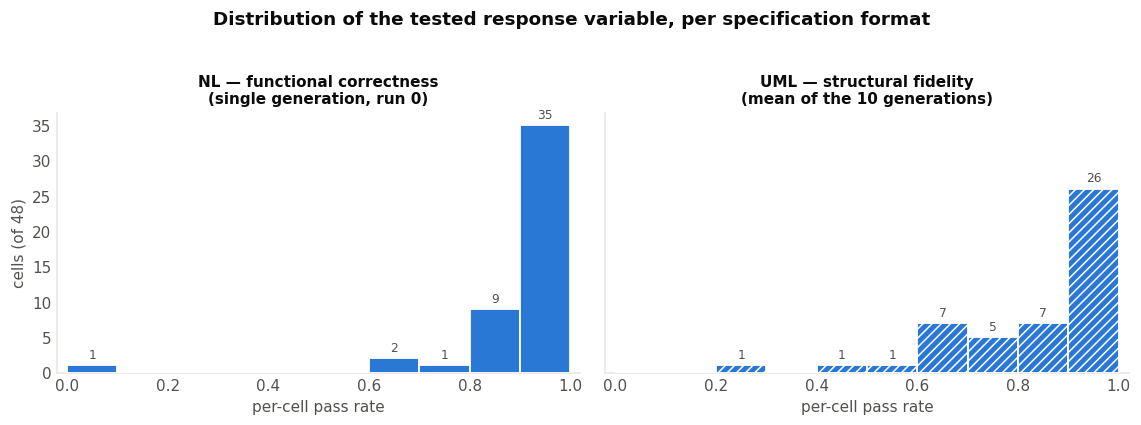

Shape of the response actually tested (n = 48 cells per condition):
        n   mean  median  at 1.0  share at 1.0   skew  distinct values
nl   48.0  0.904   0.962    24.0          0.50 -3.867             10.0
uml  48.0  0.853   0.900    12.0          0.25 -1.676             24.0


In [667]:
# ── §3.0 · why Friedman — the shape of the response variable ────────────────
# One histogram per condition of the per-cell response the tests actually run on
# (`test_case_pass_rate`): RQ1's single-generation (run0) pass rates on the left,
# RQ2's ten-run-mean pass rates on the right. Bars count how many of the 48 cells
# (12 repos x 4 models) fall in each 0.1 bin from 0 to 1. Condition follows the
# notebook's encoding: NL solid, UML hatched.
_BINS = np.arange(0, 1.0001, 0.1)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
_hist_stats = {}
for ax, cond in zip(axes, COND_ORDER):
    v = df.loc[df.condition == cond, METRIC].dropna().values
    counts, _ = np.histogram(v, bins=_BINS)          # last bin is closed on 1.0
    ax.bar(_BINS[:-1], counts, width=0.1, align="edge",
           color=MODEL_COLORS["claude"], edgecolor="white", linewidth=1.2,
           hatch=COND_HATCH[cond], zorder=3)
    for x, c in zip(_BINS[:-1], counts):
        if c:
            ax.text(x + 0.05, c + 0.6, str(c), ha="center", va="bottom",
                    fontsize=8, color=INK2, zorder=4)
    at_ceiling = int((v == 1.0).sum())
    _hist_stats[cond] = {"n": len(v), "mean": v.mean(), "median": float(np.median(v)),
                         "at 1.0": at_ceiling, "share at 1.0": at_ceiling / len(v),
                         "skew": float(pd.Series(v).skew()),
                         "distinct values": int(pd.Series(v).nunique())}
    style_ax(ax)
    ax.set_title(("NL — functional correctness\n(single generation, run 0)" if cond == "nl"
                  else "UML — structural fidelity\n(mean of the 10 generations)"),
                 fontsize=10)
    ax.set_xlabel("per-cell pass rate")
    ax.set_xlim(-0.02, 1.02)
    ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.grid(axis="y")
axes[0].set_ylabel(f"cells (of {len(df) // len(COND_ORDER)})")
fig.suptitle("Distribution of the tested response variable, per specification format",
             fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("Shape of the response actually tested (n = 48 cells per condition):")
print(pd.DataFrame(_hist_stats).T.round(3).to_string())


### 3.1  RQ1 &mdash; LLMs on natural-language behavioural specifications

**RQ1.** How do different LLMs perform in satisfying behavioral specifications expressed in
natural language?

- **H&#8320;(RQ1):** there is no significant difference among the LLMs in functional-correctness
  unit-test pass rate when generating code from natural-language specifications.
- **H&#8321;(RQ1):** at least one LLM differs significantly from the others in
  functional-correctness pass rate under natural-language specifications.

Analysed entirely within the NL condition. Tests H₀ with Friedman; the descriptive means
give a context ordering, not a tested ranking.


In [668]:
# RQ1 is stated on pass@1 — tabulate it (and its tie load) before the test
nl_p1, nl_p1_tied = pass_at_1_table("nl")


**NL — pass@1 per repo × model** (Chen et al. 2021: a generation scores 1 only if it passes *every* test). Denominator here is 1 generation, so the value is binary 0/1. Last row counts, per model, the repos where that model sits in a ≥3-model tie.

,Claude,DeepSeek,Gemini,GPT,Largest tie,≥3 tied
asimov,0.000000,1.000000,1.000000,0.000000,2,–
NexusCtrl,1.000000,1.000000,0.000000,0.000000,2,–
new_banking_system,0.000000,1.000000,1.000000,1.000000,3,✓
student-management-system,0.000000,0.000000,0.000000,0.000000,4,✓
kanchi,0.000000,0.000000,0.000000,0.000000,4,✓
AmazonCloneEcommerceProjectUsingDjangoReact,1.000000,1.000000,1.000000,1.000000,4,✓
student-management-using-django,1.000000,1.000000,1.000000,1.000000,4,✓
library-service-api,1.000000,0.000000,1.000000,1.000000,3,✓
planty,1.000000,1.000000,1.000000,1.000000,4,✓
Inventory-Management-System,0.000000,0.000000,0.000000,0.000000,4,✓


≥3 of the 4 models are tied in **9 of 12 repos** (75%). Ranking the models on pass@1 would therefore rest mostly on tied blocks, which carry no rank information — which is why the Friedman test below uses `test_case_pass_rate` (continuous partial credit) as its response instead. pass@1 is reported as the headline correctness number, not as the ranking response.

In [669]:
corr_results["nl"] = correctness_rq(
    "nl", "functional-correctness pass rate", "NL / behavioural")

# the test's working: per-repo values, within-repo ranks, rank sums
nl_rank_tbl, nl_rank_sums = friedman_rank_table("nl")


[NL]  NL / behavioural
response = functional-correctness pass rate   (n = 12 repos, k = 4 models)

Descriptives (Rank orders the means; 1 = highest pass rate):


Model,Mean,SD,n,Rank
Claude,0.940,0.070,12,1
Gemini,0.935,0.077,12,2
GPT,0.916,0.101,12,3
DeepSeek,0.825,0.288,12,4



Friedman:          chi2(3) = 3.000,  p = 0.3916
Iman–Davenport:    F(3,33) = 1.000,  p = 0.4051   (cross-check)
Decision at alpha = 0.05:  fail to reject H0 — no detectable difference among models.


**NL — Friedman rank table** (`test_case_pass_rate`, n = 12 repos, k = 4 models). Ranks are assigned *within each repo*, **1 = highest pass rate**, ties averaged.

**Rank sums** — this is what &chi;&sup2; is computed from. Lower = better here; H₀ expects all four at *n*(*k*+1)/2 = **30**.

Model,Rank sum,Mean rank,Expected under H₀,Deviation
Gemini,26.0,2.17,30,-4.0
Claude,29.5,2.46,30,-0.5
GPT,31.0,2.58,30,+1.0
DeepSeek,33.5,2.79,30,+3.5


Parity check &mdash; &chi;&sup2; rebuilt from the rank sums above = **3.000** (tie correction *c* = 0.4917); scipy reports **3.000** &rarr; **MATCH**. The rank table is therefore the exact input to the test reported above.

### 3.2  RQ2 &mdash; LLMs on UML structural specifications

**RQ2.** How do different LLMs perform in satisfying structural specifications expressed in UML?

- **H&#8320;(RQ2):** there is no significant difference among the LLMs in structural-fidelity
  unit-test pass rate when generating code from UML specifications.
- **H&#8321;(RQ2):** at least one LLM differs significantly from the others in structural-fidelity
  pass rate under UML specifications.

Analysed entirely within the UML condition. Tests H₀ with Friedman; the descriptive means
give a context ordering, not a tested ranking.

The response variable here is itself a **10-generation average** per (repo, model) — see §2.2 — not a single run, unlike RQ1's NL response.


In [670]:
# RQ2 is stated on pass@1 — tabulate it (and its tie load) before the test
uml_p1, uml_p1_tied = pass_at_1_table("uml")


**UML — pass@1 per repo × model** (Chen et al. 2021: a generation scores 1 only if it passes *every* test). Denominator here is 10–10 generations, so the value is a fraction. Last row counts, per model, the repos where that model sits in a ≥3-model tie.

,Claude,DeepSeek,Gemini,GPT,Largest tie,≥3 tied
asimov,0.700000,0.100000,0.000000,0.000000,2,–
NexusCtrl,1.000000,0.900000,1.000000,0.200000,2,–
new_banking_system,0.800000,0.800000,1.000000,1.000000,2,–
student-management-system,0.000000,0.900000,0.500000,1.000000,1,–
kanchi,0.700000,0.200000,0.000000,1.000000,1,–
AmazonCloneEcommerceProjectUsingDjangoReact,1.000000,0.300000,0.300000,0.800000,2,–
student-management-using-django,0.600000,1.000000,0.400000,0.200000,1,–
library-service-api,1.000000,0.900000,0.600000,1.000000,2,–
planty,1.000000,0.800000,0.800000,0.700000,2,–
Inventory-Management-System,0.500000,0.300000,0.000000,0.700000,1,–


≥3 of the 4 models are tied in only **1 of 12 repos** (8%), because this format's pass@1 is a fraction over several generations rather than a single binary outcome. Ties are therefore *not* the reason the Friedman test below uses `test_case_pass_rate`; that choice is kept for consistency with the other format.

In [671]:
corr_results["uml"] = correctness_rq(
    "uml", "structural-fidelity pass rate", "UML / structural")

# the test's working: per-repo values, within-repo ranks, rank sums
uml_rank_tbl, uml_rank_sums = friedman_rank_table("uml")


[UML]  UML / structural
response = structural-fidelity pass rate   (n = 12 repos, k = 4 models)

Descriptives (Rank orders the means; 1 = highest pass rate):


Model,Mean,SD,n,Rank
Claude,0.920,0.094,12,1
GPT,0.857,0.147,12,2
Gemini,0.820,0.230,12,3
DeepSeek,0.814,0.172,12,4



Friedman:          chi2(3) = 5.087,  p = 0.1655
Iman–Davenport:    F(3,33) = 1.810,  p = 0.1645   (cross-check)
Decision at alpha = 0.05:  fail to reject H0 — no detectable difference among models.


**UML — Friedman rank table** (`test_case_pass_rate`, n = 12 repos, k = 4 models). Ranks are assigned *within each repo*, **1 = highest pass rate**, ties averaged.

**Rank sums** — this is what &chi;&sup2; is computed from. Lower = better here; H₀ expects all four at *n*(*k*+1)/2 = **30**.

Model,Rank sum,Mean rank,Expected under H₀,Deviation
Claude,23.5,1.96,30,-6.5
GPT,28.0,2.33,30,-2.0
Gemini,31.5,2.62,30,+1.5
DeepSeek,37.0,3.08,30,+7.0


Parity check &mdash; &chi;&sup2; rebuilt from the rank sums above = **5.087** (tie correction *c* = 0.9583); scipy reports **5.087** &rarr; **MATCH**. The rank table is therefore the exact input to the test reported above.

## 4.  RQ3 &mdash; does specification representation change how LLMs rank?

**RQ3.** Does specification representation change how LLMs rank on internal and
developer-perceived code quality?

This question compares each model's ranking under natural language against its ranking under UML,
to see whether the specification format changes the ordering. It is posed as a **descriptive**
question &mdash; unlike RQ1 and RQ2 it states no H&#8320;/H&#8321; pair, so **no hypothesis test is
run here**. What the section produces is the rankings themselves, a measure of whether those
rankings are even coherent, and a per-metric read of how far they move NL &rarr; UML.

RQ3 spans **two quality dimensions**, and both go through the **identical chain**. Only the
metrics and the number of generations behind one cell differ:

| | 4.1 Internal quality | 4.2 Developer-perceived quality |
|---|---|---|
| Instrument | SonarQube, static analysis | human rater, rubric |
| Generations per cell | **10, averaged** (&sect;2.3) | **1**, selected by the &sect;2.4 median rule |
| Metrics | 6 | 5 |
| Direction | lower better (Size is descriptive) | higher better (proximity rank: lower better) |
| Chain | identical | identical |

**The chain.**

1. **Descriptives** &mdash; mean (SD) per model &times; condition.
2. **Kendall's *W*, per condition** &mdash; do the metrics agree on one model ordering? Judges =
   the metrics, items = the 4 models, each judge ranking them by **that metric's model means
   across the 12 repos** (1 = best, direction-aligned). High *W* = the metrics concur, so a
   coherent "best model" exists; low *W* = they disagree, so there is no single best and it
   depends what you measure. This is a **precondition**: it decides whether the per-metric
   rankings may be collapsed into one ranking at all. Directionless metrics (Size/NCLOC) are
   excluded &mdash; more code is not *worse* code.
3. **Spearman &rho; per metric** &mdash; the NL ordering against the UML ordering, one &rho; per
   metric, plus **bump charts** of the same shift. &rho; = 1 means the four models keep the
   identical order across formats; a lower &rho; means the format rearranges which model leads on
   that axis. &rho; is computed over the 4 model means, so *n* = 4 and no p-value is attainable
   &mdash; which is consistent with RQ3 being a descriptive question.


In [672]:
# ── §4 · helpers — one chain, run twice (internal quality, then human rating) ─
# Every function below takes a metric map, so both dimensions go through the
# IDENTICAL analysis; only the metrics and the number of generations behind a
# cell differ. Chain per dimension:
#   descriptives -> Kendall's W per condition -> Spearman rho per metric
#   + bump chart. Descriptive throughout: RQ3 states no hypothesis, so no test.
from scipy.stats import spearmanr, chi2 as _chi2d
from IPython.display import display, Markdown

IQ_METRICS = {
    "ncloc":                    "Size (NCLOC)",
    "cognitive_kloc":           "Cognitive cplx / KLOC",
    "cyclomatic_kloc":          "Cyclomatic cplx / KLOC",
    "bugs_kloc":                "Bugs / KLOC",
    "vuln_kloc":                "Vulns / KLOC",
    "smells_kloc":              "Code smells / KLOC",
    "duplicated_lines_density": "Duplication %",
    "comment_lines_density":    "Comment density %",
}
H_METRICS = {
    "h_readability":     "Readability",
    "h_maintainability": "Maintainability",
    "h_proximity_rank":  "Human-proximity rank",
}

# True = lower is better, False = higher is better, None = descriptive (no direction)
METRIC_DIR = {
    # Size and comment density are DESCRIPTIVE: neither more code nor more
    # comments is straightforwardly better, and comment density is 0.0% in
    # over half the cells, so its ordering would be mostly noise. Both are
    # reported but excluded as Kendall's W judges.
    "ncloc": None,
    "comment_lines_density": None,
    "cognitive_kloc": True, "cyclomatic_kloc": True,
    "bugs_kloc": True, "vuln_kloc": True,
    "smells_kloc": True, "duplicated_lines_density": True,
    "h_readability": False, "h_maintainability": False,
    "h_proximity_rank": True,      # rank 1 = closest to human-written code
}

def _fmt_for(key):
    """1 decimal for the big count metrics, 2 for the 1-5 rating scales."""
    v = df[key].abs().max()
    return "{:.1f}" if pd.notna(v) and v >= 10 else "{:.2f}"

def _means(cond, key):
    return df[df.condition == cond].groupby("model")[key].mean().reindex(MODEL_ORDER)

def _ranked(cond, key):
    """model means and their ranks with 1 = BEST (direction-aware; descriptive
    metrics are ranked smallest-first and flagged as such by the caller)."""
    m  = _means(cond, key)
    lb = METRIC_DIR[key]
    asc = True if lb is None else lb                 # None -> smallest = rank 1
    return m, m.rank(method="min", ascending=asc)

def _flat(means, eps=1e-9):
    return float(means.max() - means.min()) <= eps   # no spread -> no ordering


# ── 1 · descriptives ────────────────────────────────────────────────────────
def desc_table(metric_map, dim_label, n_gen_note):
    rows = []
    for cond in COND_ORDER:
        g = df[df.condition == cond].groupby("model")
        for mdl in MODEL_ORDER:
            row = {"Condition": cond.upper(), "Model": MODEL_LABEL[mdl]}
            for key, label in metric_map.items():
                f = _fmt_for(key)
                mean = g[key].mean().reindex(MODEL_ORDER)[mdl]
                sd   = g[key].std(ddof=1).reindex(MODEL_ORDER)[mdl]
                row[label] = f"{f.format(mean)} ({f.format(sd)})"
            rows.append(row)
    tbl = pd.DataFrame(rows)
    display(Markdown(
        f"**{dim_label} — descriptives.** Mean (SD) per model × condition over the "
        f"{df.repo.nunique()} repos. {n_gen_note}"))
    display(tbl.style.hide(axis="index")
              .set_caption(f"{dim_label}: mean (SD) per model and condition"))
    return tbl


# ── 2 · Kendall's W per condition — is there ONE ranking to compare? ────────
def ranking_coherence(metric_map, dim_label):
    """Judges = metrics, items = models. Each judge ranks the 4 models by that
    metric's model means across the repos (1 = best, direction-aligned).
    W = 1 -> every metric gives the same order (a coherent 'best model' exists);
    W = 0 -> the metrics disagree completely (no single best; it depends what you
    measure). Directionless metrics (Size) are excluded. Precondition diagnostic:
    it licenses or forbids collapsing the metrics into one overall ranking."""
    rows, orders = [], []
    for cond in COND_ORDER:
        judges = {label: _ranked(cond, key)[1]
                  for key, label in metric_map.items() if METRIC_DIR[key] is not None}
        R = pd.DataFrame(judges).T
        m, k = R.shape
        ranksums = R.sum(axis=0)
        S = ((ranksums - ranksums.mean()) ** 2).sum()
        W = 12 * S / (m ** 2 * (k ** 3 - k))
        chi2 = m * (k - 1) * W
        rows.append({"Condition": cond.upper(), "Metrics (judges)": m, "Models (items)": k,
                     "Kendall's W": W, "chi2(3)": chi2,
                     "p": float(_chi2d.sf(chi2, k - 1)),
                     "Agreement": ("strong" if W >= .7 else "moderate" if W >= .5
                                   else "weak" if W >= .3 else "negligible")})
        o = ranksums.sort_values()
        orders.append(f"**{cond.upper()}** consensus order: " +
                      " < ".join(f"{MODEL_LABEL[m_]} ({v:.1f})" for m_, v in o.items()))
    tbl = pd.DataFrame(rows)
    excluded = [lab for key, lab in metric_map.items() if METRIC_DIR[key] is None]

    display(Markdown(
        f"**{dim_label} — is there one ranking?** Concordance among the per-metric model "
        f"rankings: judges = the metrics, items = the {len(MODEL_ORDER)} models, each judge "
        f"ranking them by its own model means (1 = best)."
        + (f" Excluded as directionless: {', '.join(excluded)}." if excluded else "")))
    display(tbl.style
              .format({"Kendall's W": "{:.3f}", "chi2(3)": "{:.2f}", "p": "{:.3f}"})
              .hide(axis="index")
              .set_caption(f"{dim_label}: do the metrics agree on a single model ordering?"))
    display(Markdown("  \n".join(orders) +
                     "\n\n*(rank sums in brackets; all four equal = the metrics cancel out)*"))

    worst = tbl["Kendall's W"].max()
    lab   = tbl.loc[tbl["Kendall's W"].idxmax(), "Agreement"]
    if worst < 0.5:
        display(Markdown(
            f"**No single ranking exists** — strongest concordance in either condition is "
            f"W = {worst:.3f} ({lab}). A model that leads on one axis does not lead on the "
            f"others, so an overall ranking would be an artefact of how the axes were weighted. "
            f"Everything below is therefore reported **per metric**."))
    else:
        display(Markdown(
            f"**An aggregate ranking is defensible** (max W = {worst:.3f}, {lab}); the "
            f"per-metric results below can be summarised by a composite ordering."))
    return tbl


# ── 3 · ranks + Spearman rho per metric ─────────────────────────────────────
def rank_spearman(metric_map, dim_label):
    """Per metric: the 4-model ordering under each input (1 = best) and Spearman
    rho between the two orderings. Descriptive — rho is over 4 model means, so no
    p-value is attainable; the tested counterpart is the Friedman below.

    Directionless metrics are dropped, exactly as in Kendall's W and the rank
    heatmap: rho compares two ORDERINGS, and a metric with no better/worse has no
    ordering to compare — its rho would only measure whether 'smaller' stayed
    smaller, which is not a quality claim. All three rank views therefore run on
    the same metric set."""
    rank_rows, trend_rows = [], []
    ranked = {k: lab for k, lab in metric_map.items() if METRIC_DIR[k] is not None}
    for key, label in ranked.items():
        nl_mean,  nl_rank  = _ranked("nl",  key)
        uml_mean, uml_rank = _ranked("uml", key)
        f = _fmt_for(key)
        for mdl in MODEL_ORDER:
            rank_rows.append({
                "Metric": label, "Model": MODEL_LABEL[mdl],
                "NL mean":  float(f.format(nl_mean[mdl])),
                "NL rank":  int(nl_rank[mdl]),
                "UML mean": float(f.format(uml_mean[mdl])),
                "UML rank": int(uml_rank[mdl]),
                "rank Δ (UML−NL)": int(uml_rank[mdl] - nl_rank[mdl]),
            })
        # No bucketed verdict column: rho is reported raw and the reader judges
        # it. Any "stable / reshuffled / reversed" labelling would impose cutoffs
        # the data does not carry, and over n = 4 model means the difference
        # between neighbouring rho values is not meaningful enough to name.
        if _flat(nl_mean) or _flat(uml_mean):
            rho, nl_best, uml_best, changed = (
                np.nan, "— (tied)", "— (tied)", "n/a")
        else:
            rho, _ = spearmanr(nl_rank.values, uml_rank.values)
            nl_best, uml_best = MODEL_LABEL[nl_rank.idxmin()], MODEL_LABEL[uml_rank.idxmin()]
            changed  = "yes" if nl_best != uml_best else "no"
        trend_rows.append({"Metric": label, "NL best": nl_best, "UML best": uml_best,
                           "best changed": changed, "Spearman ρ (NL,UML)": rho})
    rank_tbl, trend_tbl = pd.DataFrame(rank_rows), pd.DataFrame(trend_rows)

    _dropped = [lab for k, lab in metric_map.items() if METRIC_DIR[k] is None]
    display(Markdown(
        f"**{dim_label} — model ranking per metric under each input** (1 = best; "
        f"`rank Δ > 0` = the model places comparatively worse under UML)."
        + (f" Directionless metrics are excluded, as in Kendall's *W* and the rank "
           f"heatmap: {', '.join(_dropped)}." if _dropped else "")))
    display(rank_tbl.style.format({"NL mean": "{:g}", "UML mean": "{:g}"})
              .hide(axis="index").set_caption(f"{dim_label}: per-metric ranking, NL vs UML"))
    display(Markdown(
        "**Trend shift per metric** — Spearman ρ over the 4 model ranks: +1 = identical "
        "order, 0 = unrelated, −1 = fully reversed. Reported raw and left to the reader: "
        "with *n* = 4 model means no p-value is attainable, and any cutoff into "
        "\"stable / reshuffled / reversed\" buckets would be arbitrary. A blank ρ means "
        "the metric is tied across all four models, so no ordering exists to compare."))
    display(trend_tbl.style.format({"Spearman ρ (NL,UML)": "{:+.2f}"}, na_rep="–")
              .hide(axis="index").set_caption(f"{dim_label}: NL→UML ordering shift"))
    flips = trend_tbl[trend_tbl["best changed"] == "yes"]["Metric"].tolist()
    display(Markdown(f"Leader changes on **{len(flips)}/{len(ranked)}** metrics"
                     + (f": {', '.join(flips)}." if flips else ".")))
    return rank_tbl, trend_tbl


# ── 4 · bump chart ─────────────────────────────────────────────────────────
def bump_chart(metric_map, dim_label):
    """One panel per metric; each line is a model moving from its NL rank to its
    UML rank (1 = best, on top). A crossing line = the ordering rearranges.
    Directionless metrics are dropped, as in Kendall's W, the rank heatmap and the
    Spearman table: with no better/worse there is no rank worth plotting. All four
    rank views therefore run on the same metric set."""
    metric_map = {k: lab for k, lab in metric_map.items() if METRIC_DIR[k] is not None}
    n = len(metric_map)
    ncol = 3
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(11, 3.2 * nrow), sharey=True)
    axes = np.atleast_1d(axes).ravel()
    xs = [0, 1]
    for ax, (key, label) in zip(axes, metric_map.items()):
        _, nl_rank  = _ranked("nl",  key)
        _, uml_rank = _ranked("uml", key)
        for mdl in MODEL_ORDER:
            ax.plot(xs, [nl_rank[mdl], uml_rank[mdl]], "-o", color=MODEL_COLORS[mdl],
                    lw=2.2, mfc=MODEL_COLORS[mdl], mec="white", ms=9, zorder=3)
        style_ax(ax)
        ax.set_title(label, fontsize=10)
        ax.set_xticks(xs); ax.set_xticklabels(["NL", "UML"])
        ax.set_xlim(-0.25, 1.25)
        ax.set_ylim(len(MODEL_ORDER) + 0.5, 0.5)
        ax.set_yticks(range(1, len(MODEL_ORDER) + 1))
        ax.grid(axis="y")
    for ax in axes[n:]:
        ax.set_visible(False)
    for r in range(nrow):
        axes[r * ncol].set_ylabel("rank (1 = best)")
    handles = [Patch(color=MODEL_COLORS[m], label=MODEL_LABEL[m]) for m in MODEL_ORDER]
    fig.legend(handles=handles, ncol=4, loc="lower center", frameon=False,
               bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(f"Model rank shift NL → UML — {dim_label}", fontweight="bold")
    fig.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


# ── 1b · rank heatmap — the descriptives above, reduced to their ordering ────
# Rows = metrics, columns = models, cell shaded by that model's rank on that
# metric within the condition (1 = best = lightest, 4 = worst = darkest), one
# panel per condition. Sequential single-hue ramp (SEQ_CMAP) because rank is a
# magnitude, not an identity. Ranks are direction-aware via METRIC_DIR and come
# from the same _ranked() the bump chart uses, so the two always agree.
# Directionless metrics (Size, Comment density) are DROPPED: with no better/worse
# there is no rank to shade, so shading them would invent an ordering. The rows
# shown are exactly the ones Kendall's W judges.
def rank_heatmap(metric_map, dim_label):
    keys   = [k for k in metric_map if METRIC_DIR[k] is not None]
    labels = [metric_map[k] for k in keys]
    k_mod  = len(MODEL_ORDER)

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 0.52 * len(keys) + 2.4),
                             sharey=True)
    for ax, cond in zip(axes, COND_ORDER):
        R = np.array([_ranked(cond, key)[1].reindex(MODEL_ORDER).values
                      for key in keys], dtype=float)
        M = np.array([_ranked(cond, key)[0].reindex(MODEL_ORDER).values
                      for key in keys], dtype=float)

        ax.imshow(R, cmap=SEQ_CMAP, vmin=1, vmax=k_mod, aspect="auto")
        # 2px surface gap between cells, as elsewhere in the notebook
        ax.set_xticks(np.arange(-0.5, k_mod, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, len(keys), 1), minor=True)
        ax.grid(which="minor", color="white", linewidth=2)
        ax.grid(which="major", visible=False)
        ax.tick_params(which="minor", length=0)

        for r, key in enumerate(keys):
            f = _fmt_for(key)
            for c in range(k_mod):
                # ink on the light end, white on the dark end — contrast, not hue
                col = "white" if R[r, c] >= 3 else INK
                ax.text(c, r - 0.13, f"{int(R[r, c])}", ha="center", va="center",
                        fontsize=11, fontweight="bold", color=col)
                ax.text(c, r + 0.24, f.format(M[r, c]), ha="center", va="center",
                        fontsize=7.5, color=col, alpha=0.85)

        ax.set_xticks(range(k_mod))
        ax.set_xticklabels([MODEL_LABEL[m] for m in MODEL_ORDER])
        ax.set_title(cond.upper(), fontsize=10)
        ax.tick_params(length=0)
        for s in ax.spines.values():
            s.set_visible(False)

    axes[0].set_yticks(range(len(keys)))
    axes[0].set_yticklabels(labels)

    handles = [Patch(facecolor=SEQ_CMAP((i - 1) / (k_mod - 1)), edgecolor="white",
                     label=f"{i}" + (" = best" if i == 1 else
                                     " = worst" if i == k_mod else ""))
               for i in range(1, k_mod + 1)]
    fig.legend(handles=handles, ncol=k_mod, loc="lower center", frameon=False,
               title="rank within condition", bbox_to_anchor=(0.5, -0.04))
    fig.suptitle(f"Model rank per metric — {dim_label}", fontweight="bold")
    fig.tight_layout(rect=[0, 0.04, 1, 0.94])
    plt.show()


### 4.1  Internal quality (SonarQube, 10 iterations averaged)

Measured directly on the generated source &mdash; no conformance adapter sits between the code and
the metric. Raw counts scale with program size, so every count-based metric is **per-KLOC
normalised** (Setup); size and the two density metrics are read as-is.

| Metric | Axis | Direction |
|---|---|---|
| Size (NCLOC) | size | descriptive |
| Cognitive complexity / KLOC | complexity | lower better |
| Cyclomatic complexity / KLOC | complexity | lower better |
| Bugs / KLOC | reliability | lower better |
| Vulnerabilities / KLOC | security | lower better |
| Code smells / KLOC | maintainability | lower better |
| Duplication % | maintainability | lower better |
| Comment density % | documentation | descriptive |


In [673]:
# 1 · descriptives
iq_desc = desc_table(IQ_METRICS, "Internal quality",
                     "Each cell is the mean of 10 SonarQube runs (§2.3).")


**Internal quality — descriptives.** Mean (SD) per model × condition over the 12 repos. Each cell is the mean of 10 SonarQube runs (§2.3).

Condition,Model,Size (NCLOC),Cognitive cplx / KLOC,Cyclomatic cplx / KLOC,Bugs / KLOC,Vulns / KLOC,Code smells / KLOC,Duplication %,Comment density %
NL,Claude,1282.7 (649.1),161.5 (32.7),223.5 (55.2),0.07 (0.14),0.80 (1.31),10.4 (8.0),1.1 (1.9),2.4 (2.4)
NL,DeepSeek,473.0 (153.1),178.2 (88.6),201.3 (85.9),0.92 (1.45),0.26 (0.49),14.0 (11.2),0.6 (1.2),6.3 (2.4)
NL,Gemini,300.1 (248.3),155.5 (27.0),256.1 (71.6),0.05 (0.13),0.55 (1.68),15.4 (21.2),0.4 (0.7),0.1 (0.3)
NL,GPT,690.5 (334.4),163.5 (24.0),255.7 (48.1),0.04 (0.08),0.06 (0.15),8.8 (4.0),0.9 (1.6),0.1 (0.2)
UML,Claude,549.0 (490.0),107.2 (95.5),181.4 (92.4),0.30 (0.78),0.00 (0.00),29.6 (49.7),2.4 (3.2),1.8 (1.8)
UML,DeepSeek,406.0 (330.0),76.6 (56.7),160.9 (95.5),0.11 (0.26),0.00 (0.00),36.1 (61.1),2.3 (4.4),2.9 (2.0)
UML,Gemini,282.3 (220.1),48.4 (46.9),179.0 (108.1),0.06 (0.15),0.00 (0.00),64.2 (79.1),4.3 (11.3),0.2 (0.3)
UML,GPT,595.6 (367.3),157.5 (83.0),227.8 (93.1),0.08 (0.23),0.00 (0.00),28.2 (34.5),3.6 (5.2),0.2 (0.4)


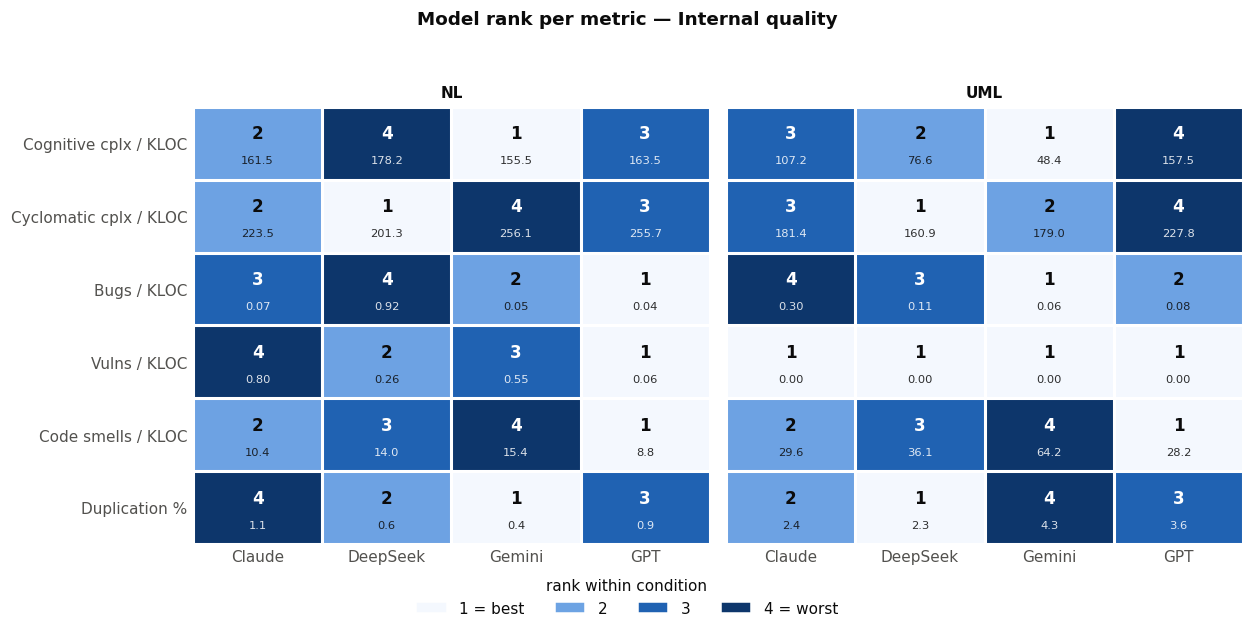

In [674]:
# 1b · the same descriptives, reduced to their ordering
rank_heatmap(IQ_METRICS, "Internal quality")

In [675]:
# 2 · Kendall's W per condition — is there one ranking to compare?
iq_coherence = ranking_coherence(IQ_METRICS, "Internal quality")


**Internal quality — is there one ranking?** Concordance among the per-metric model rankings: judges = the metrics, items = the 4 models, each judge ranking them by its own model means (1 = best). Excluded as directionless: Size (NCLOC), Comment density %.

Condition,Metrics (judges),Models (items),Kendall's W,chi2(3),p,Agreement
NL,6,4,0.078,1.40,0.706,negligible
UML,6,4,0.061,1.10,0.777,negligible


**NL** consensus order: GPT (12.0) < Gemini (15.0) < DeepSeek (16.0) < Claude (17.0)  
**UML** consensus order: DeepSeek (11.0) < Gemini (13.0) < Claude (15.0) < GPT (15.0)

*(rank sums in brackets; all four equal = the metrics cancel out)*

**No single ranking exists** — strongest concordance in either condition is W = 0.078 (negligible). A model that leads on one axis does not lead on the others, so an overall ranking would be an artefact of how the axes were weighted. Everything below is therefore reported **per metric**.

In [676]:
# 3 · ranks + Spearman rho per metric
iq_rank_tbl, iq_trend_tbl = rank_spearman(IQ_METRICS, "Internal quality")


**Internal quality — model ranking per metric under each input** (1 = best; `rank Δ > 0` = the model places comparatively worse under UML). Directionless metrics are excluded, as in Kendall's *W* and the rank heatmap: Size (NCLOC), Comment density %.

Metric,Model,NL mean,NL rank,UML mean,UML rank,rank Δ (UML−NL)
Cognitive cplx / KLOC,Claude,161.5,2,107.2,3,1
Cognitive cplx / KLOC,DeepSeek,178.2,4,76.6,2,-2
Cognitive cplx / KLOC,Gemini,155.5,1,48.4,1,0
Cognitive cplx / KLOC,GPT,163.5,3,157.5,4,1
Cyclomatic cplx / KLOC,Claude,223.5,2,181.4,3,1
Cyclomatic cplx / KLOC,DeepSeek,201.3,1,160.9,1,0
Cyclomatic cplx / KLOC,Gemini,256.1,4,179,2,-2
Cyclomatic cplx / KLOC,GPT,255.7,3,227.8,4,1
Bugs / KLOC,Claude,0.07,3,0.3,4,1
Bugs / KLOC,DeepSeek,0.92,4,0.11,3,-1


**Trend shift per metric** — Spearman ρ over the 4 model ranks: +1 = identical order, 0 = unrelated, −1 = fully reversed. Reported raw and left to the reader: with *n* = 4 model means no p-value is attainable, and any cutoff into "stable / reshuffled / reversed" buckets would be arbitrary. A blank ρ means the metric is tied across all four models, so no ordering exists to compare.

Metric,NL best,UML best,best changed,"Spearman ρ (NL,UML)"
Cognitive cplx / KLOC,Gemini,Gemini,no,+0.40
Cyclomatic cplx / KLOC,DeepSeek,DeepSeek,no,+0.40
Bugs / KLOC,GPT,Gemini,yes,+0.60
Vulns / KLOC,— (tied),— (tied),n/a,–
Code smells / KLOC,GPT,GPT,no,+1.00
Duplication %,Gemini,DeepSeek,yes,-0.40


Leader changes on **2/6** metrics: Bugs / KLOC, Duplication %.

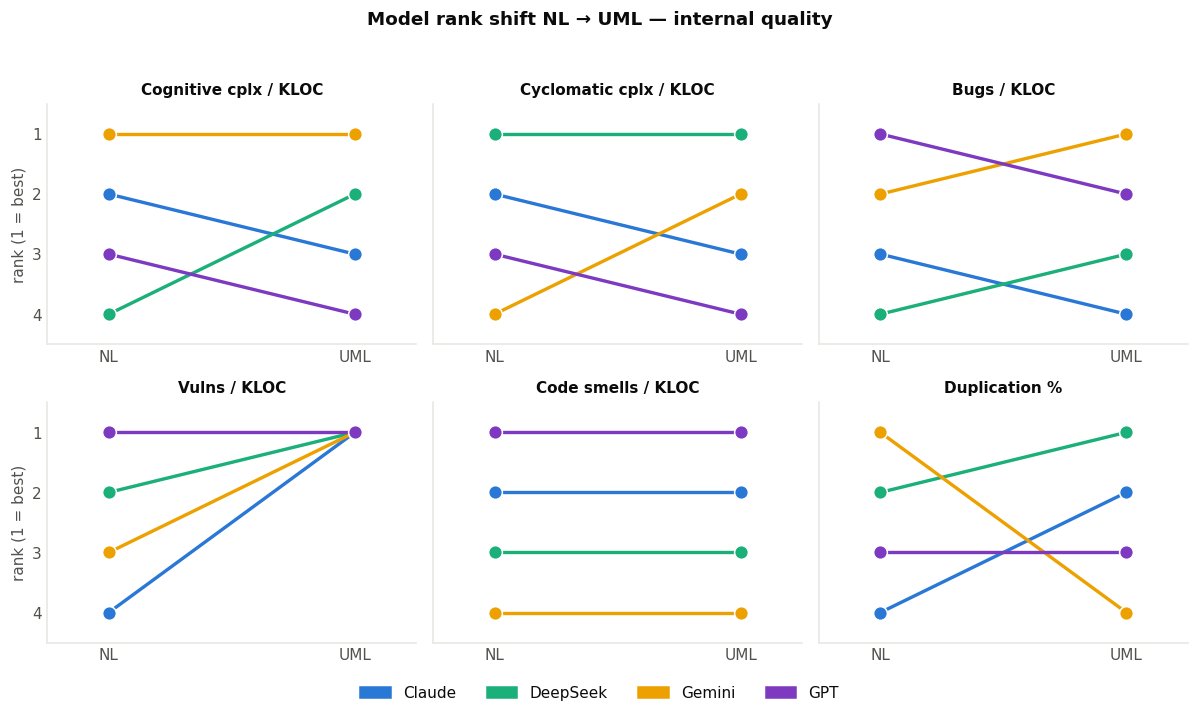

In [677]:
# 3b · bump charts — the same rank shift, visually
bump_chart(IQ_METRICS, "internal quality")


### 4.2  Developer-perceived quality (human rating, single iteration)

Same four steps as 4.1, on the human rubric scores. One rating per (repo, condition, model) &mdash;
the rated generation is the one selected in &sect;2.4, so there is nothing to average over runs.

| Metric | Scale | Direction |
|---|---|---|
| Readability | 1&ndash;5 | higher better |
| Maintainability | 1&ndash;5 | higher better |
| Human-proximity rank | 1&ndash;4, forced ranking of the models | lower better (1 = closest to human-written) |

One property to keep in mind when reading the tables: **Human-proximity rank** is not an independent
draw like the two 1&ndash;5 scores. It is a within-cell forced ranking of the four models, so each
(repo, condition) block sums to 10 and the four values are negatively correlated by construction.

In [678]:
# 1 · descriptives
h_desc = desc_table(H_METRICS, "Developer-perceived quality",
                    "Each cell is a single human rating of the §2.4-selected generation.")


**Developer-perceived quality — descriptives.** Mean (SD) per model × condition over the 12 repos. Each cell is a single human rating of the §2.4-selected generation.

Condition,Model,Readability,Maintainability,Human-proximity rank
NL,Claude,4.60 (0.23),4.67 (0.78),2.58 (1.08)
NL,DeepSeek,4.77 (0.23),4.00 (1.04),2.33 (1.07)
NL,Gemini,4.73 (0.21),4.33 (0.98),2.00 (1.21)
NL,GPT,4.68 (0.21),3.92 (1.38),3.08 (1.00)
UML,Claude,4.83 (0.15),4.75 (0.62),2.08 (1.24)
UML,DeepSeek,4.88 (0.16),4.17 (0.94),2.50 (1.00)
UML,Gemini,4.88 (0.09),4.25 (0.87),2.42 (1.08)
UML,GPT,4.80 (0.13),4.67 (0.65),3.00 (1.13)


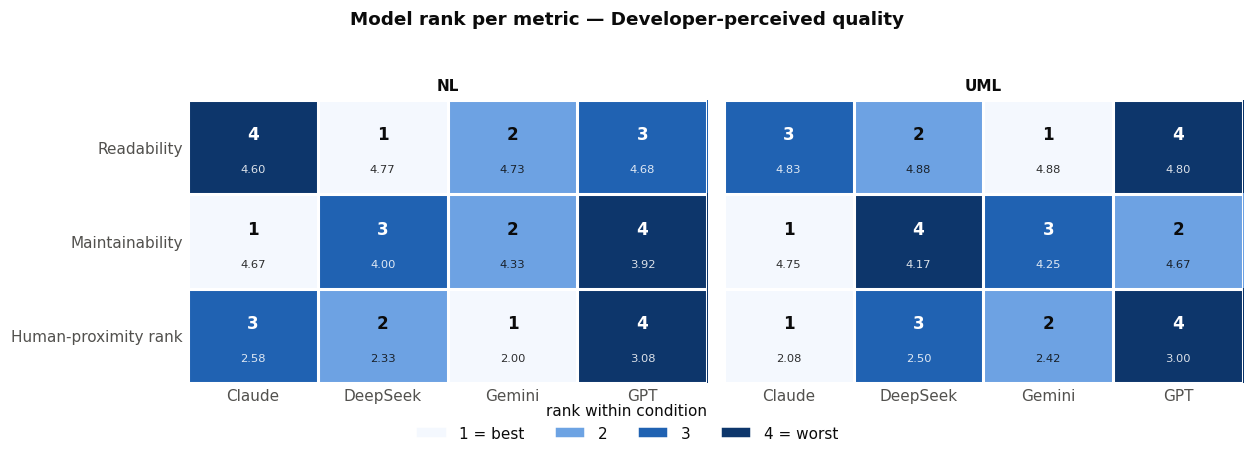

In [679]:
# 1b · the same descriptives, reduced to their ordering
rank_heatmap(H_METRICS, "Developer-perceived quality")

In [680]:
# 2 · Kendall's W per condition — is there one ranking to compare?
h_coherence = ranking_coherence(H_METRICS, "Developer-perceived quality")


**Developer-perceived quality — is there one ranking?** Concordance among the per-metric model rankings: judges = the metrics, items = the 4 models, each judge ranking them by its own model means (1 = best).

Condition,Metrics (judges),Models (items),Kendall's W,chi2(3),p,Agreement
NL,3,4,0.467,4.20,0.241,weak
UML,3,4,0.378,3.40,0.334,weak


**NL** consensus order: Gemini (5.0) < DeepSeek (6.0) < Claude (8.0) < GPT (11.0)  
**UML** consensus order: Claude (5.0) < Gemini (6.0) < DeepSeek (9.0) < GPT (10.0)

*(rank sums in brackets; all four equal = the metrics cancel out)*

**No single ranking exists** — strongest concordance in either condition is W = 0.467 (weak). A model that leads on one axis does not lead on the others, so an overall ranking would be an artefact of how the axes were weighted. Everything below is therefore reported **per metric**.

In [681]:
# 3 · ranks + Spearman rho per metric
h_rank_tbl, h_trend_tbl = rank_spearman(H_METRICS, "Developer-perceived quality")


**Developer-perceived quality — model ranking per metric under each input** (1 = best; `rank Δ > 0` = the model places comparatively worse under UML).

Metric,Model,NL mean,NL rank,UML mean,UML rank,rank Δ (UML−NL)
Readability,Claude,4.6,4,4.83,3,-1
Readability,DeepSeek,4.77,1,4.88,2,1
Readability,Gemini,4.73,2,4.88,1,-1
Readability,GPT,4.68,3,4.8,4,1
Maintainability,Claude,4.67,1,4.75,1,0
Maintainability,DeepSeek,4,3,4.17,4,1
Maintainability,Gemini,4.33,2,4.25,3,1
Maintainability,GPT,3.92,4,4.67,2,-2
Human-proximity rank,Claude,2.58,3,2.08,1,-2
Human-proximity rank,DeepSeek,2.33,2,2.5,3,1


**Trend shift per metric** — Spearman ρ over the 4 model ranks: +1 = identical order, 0 = unrelated, −1 = fully reversed. Reported raw and left to the reader: with *n* = 4 model means no p-value is attainable, and any cutoff into "stable / reshuffled / reversed" buckets would be arbitrary. A blank ρ means the metric is tied across all four models, so no ordering exists to compare.

Metric,NL best,UML best,best changed,"Spearman ρ (NL,UML)"
Readability,DeepSeek,Gemini,yes,+0.60
Maintainability,Claude,Claude,no,+0.40
Human-proximity rank,Gemini,Claude,yes,+0.40


Leader changes on **2/3** metrics: Readability, Human-proximity rank.

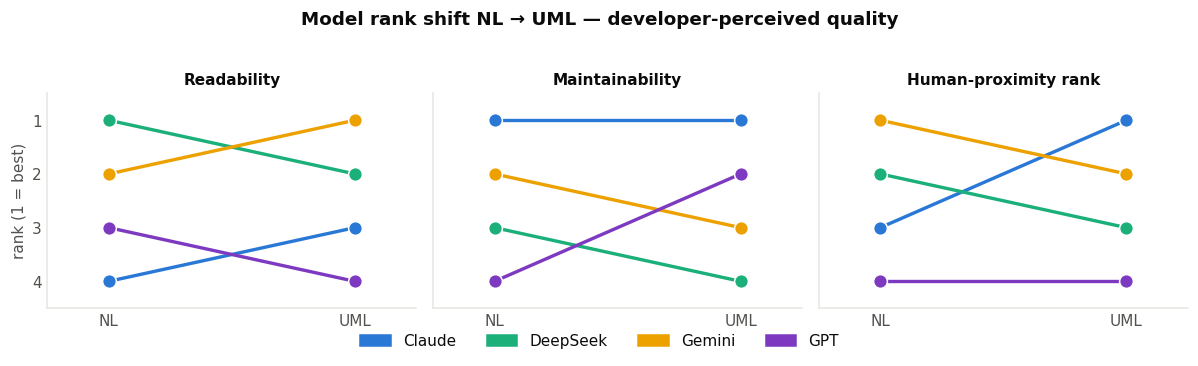

In [682]:
# 3b · bump charts — the same rank shift, visually
bump_chart(H_METRICS, "developer-perceived quality")
